In [1]:
# Figure 1: Global heatmap of AI-meteorology studies published and GDP per capita
# Nathan Erickson

In [2]:
# Import modules
import os
import string
import math
import numpy as np
import pandas as pd
import geopandas
import matplotlib as mpl
import matplotlib.pyplot as plt
import cartopy
import seaborn as sns

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.io.shapereader as shpreader

from matplotlib.colors import Normalize,LogNorm,CenteredNorm

In [3]:
# Set directory structure
base_dir = '' # Fill your directory here
data_dir = os.path.join(base_dir,'Data')
img_dir = os.path.join(base_dir,'FiguresForPaper')
if not os.path.exists(img_dir):
    os.mkdir(img_dir)

In [4]:
# Load geospatial reference dataframe
resolution = '10m'
category = 'cultural'
name = 'admin_0_countries'
shpfilename = shpreader.natural_earth(resolution, category, name)

# read the shapefile using geopandas
df_shp = geopandas.read_file(shpfilename)


country_counts = {
    'Portugal':1,'South Korea':14,'Antarctica':12,
    'China':214,'India':15,'Russia':1,'France':12,
    'Germany':20,'Taiwan':3,'Switzerland':10,'Japan':10,
    'United Kingdom':11,'Netherlands':1,'Canada':7,'Brazil':13,
    'Italy':5,'Finland':2,'Spain':9,'Benin':3,
    'Turkey':2,'Indonesia':5,'Australia':17,'Ireland':1,
    'Nigeria':1,'Hungary':1,'Poland':3,'Argentina':2,
    'Kenya':2,'Romania':1,'Kiribati':1,'New Zealand':3,
    'Iran':5,'Ethiopia':1,'Malaysia':3,'Pakistan':3,
    'Vietnam':1,'Grenada':1,'Morocco':1,'Bangladesh':1,
    'Hong Kong S.A.R.':1,'Mexico':1,'Austria':2,'Thailand':1,
    'Norway':1,'Turkmenistan':1,'Saudi Arabia':2,'United States of America':165
} # Data collected from 18 journals listed in study

In [5]:
# Load GDP per capita data; make dictionary for plotting
os.chdir('Data/')
gdp_data = pd.read_csv('GDP_Per_Capita.csv')

In [18]:
# Compute correlations
cc = np.corrcoef(gdp_data['GDP Per Capita'], gdp_data['# Studies'])

In [7]:
# Compute publications/capita, publications/land area, publications/GDP
pubs_per_capita = (gdp_data ['# Studies']) / gdp_data['Population']
pubs_per_landarea = (gdp_data['# Studies']) / gdp_data['Land Area']
pubs_per_gdp = (gdp_data['# Studies']) / gdp_data['GDP']

In [8]:
# Normalize the data to prepare for plotting; set up dictionaries
gdp_dict = dict(zip(gdp_data['Country Name'],gdp_data['GDP Per Capita']))

gdp_mean = np.mean(list(gdp_dict.values()))
gdp_min = np.min(list(gdp_dict.values()))
gdp_max = np.max(list(gdp_dict.values()))

gdp_norm = {k: (v - gdp_min) / (gdp_max - gdp_min) for k,v in gdp_dict.items()} # Normalize the values

per_capita_dict = dict(zip(gdp_data['Country Name'],pubs_per_capita))
per_landarea_dict = dict(zip(gdp_data['Country Name'],pubs_per_landarea))
per_gdp_dict = dict(zip(gdp_data['Country Name'],pubs_per_gdp))

In [9]:
# Manual scaling here to get these values onto O(1-10)
per_capita_logdict = dict(zip(gdp_data['Country Name'], (np.array(list(per_capita_dict.values())) * 1e8) + 1 ) )
per_landarea_logdict = dict(zip(gdp_data['Country Name'], (np.array(list(per_landarea_dict.values())) *1e5) + 1 ) )
per_gdp_logdict = dict(zip(gdp_data['Country Name'], (np.array(list(per_gdp_dict.values())) * 1e12) + 1  ) )

Text(0.5, 1.0, 'D) AI Applications Per GDP')

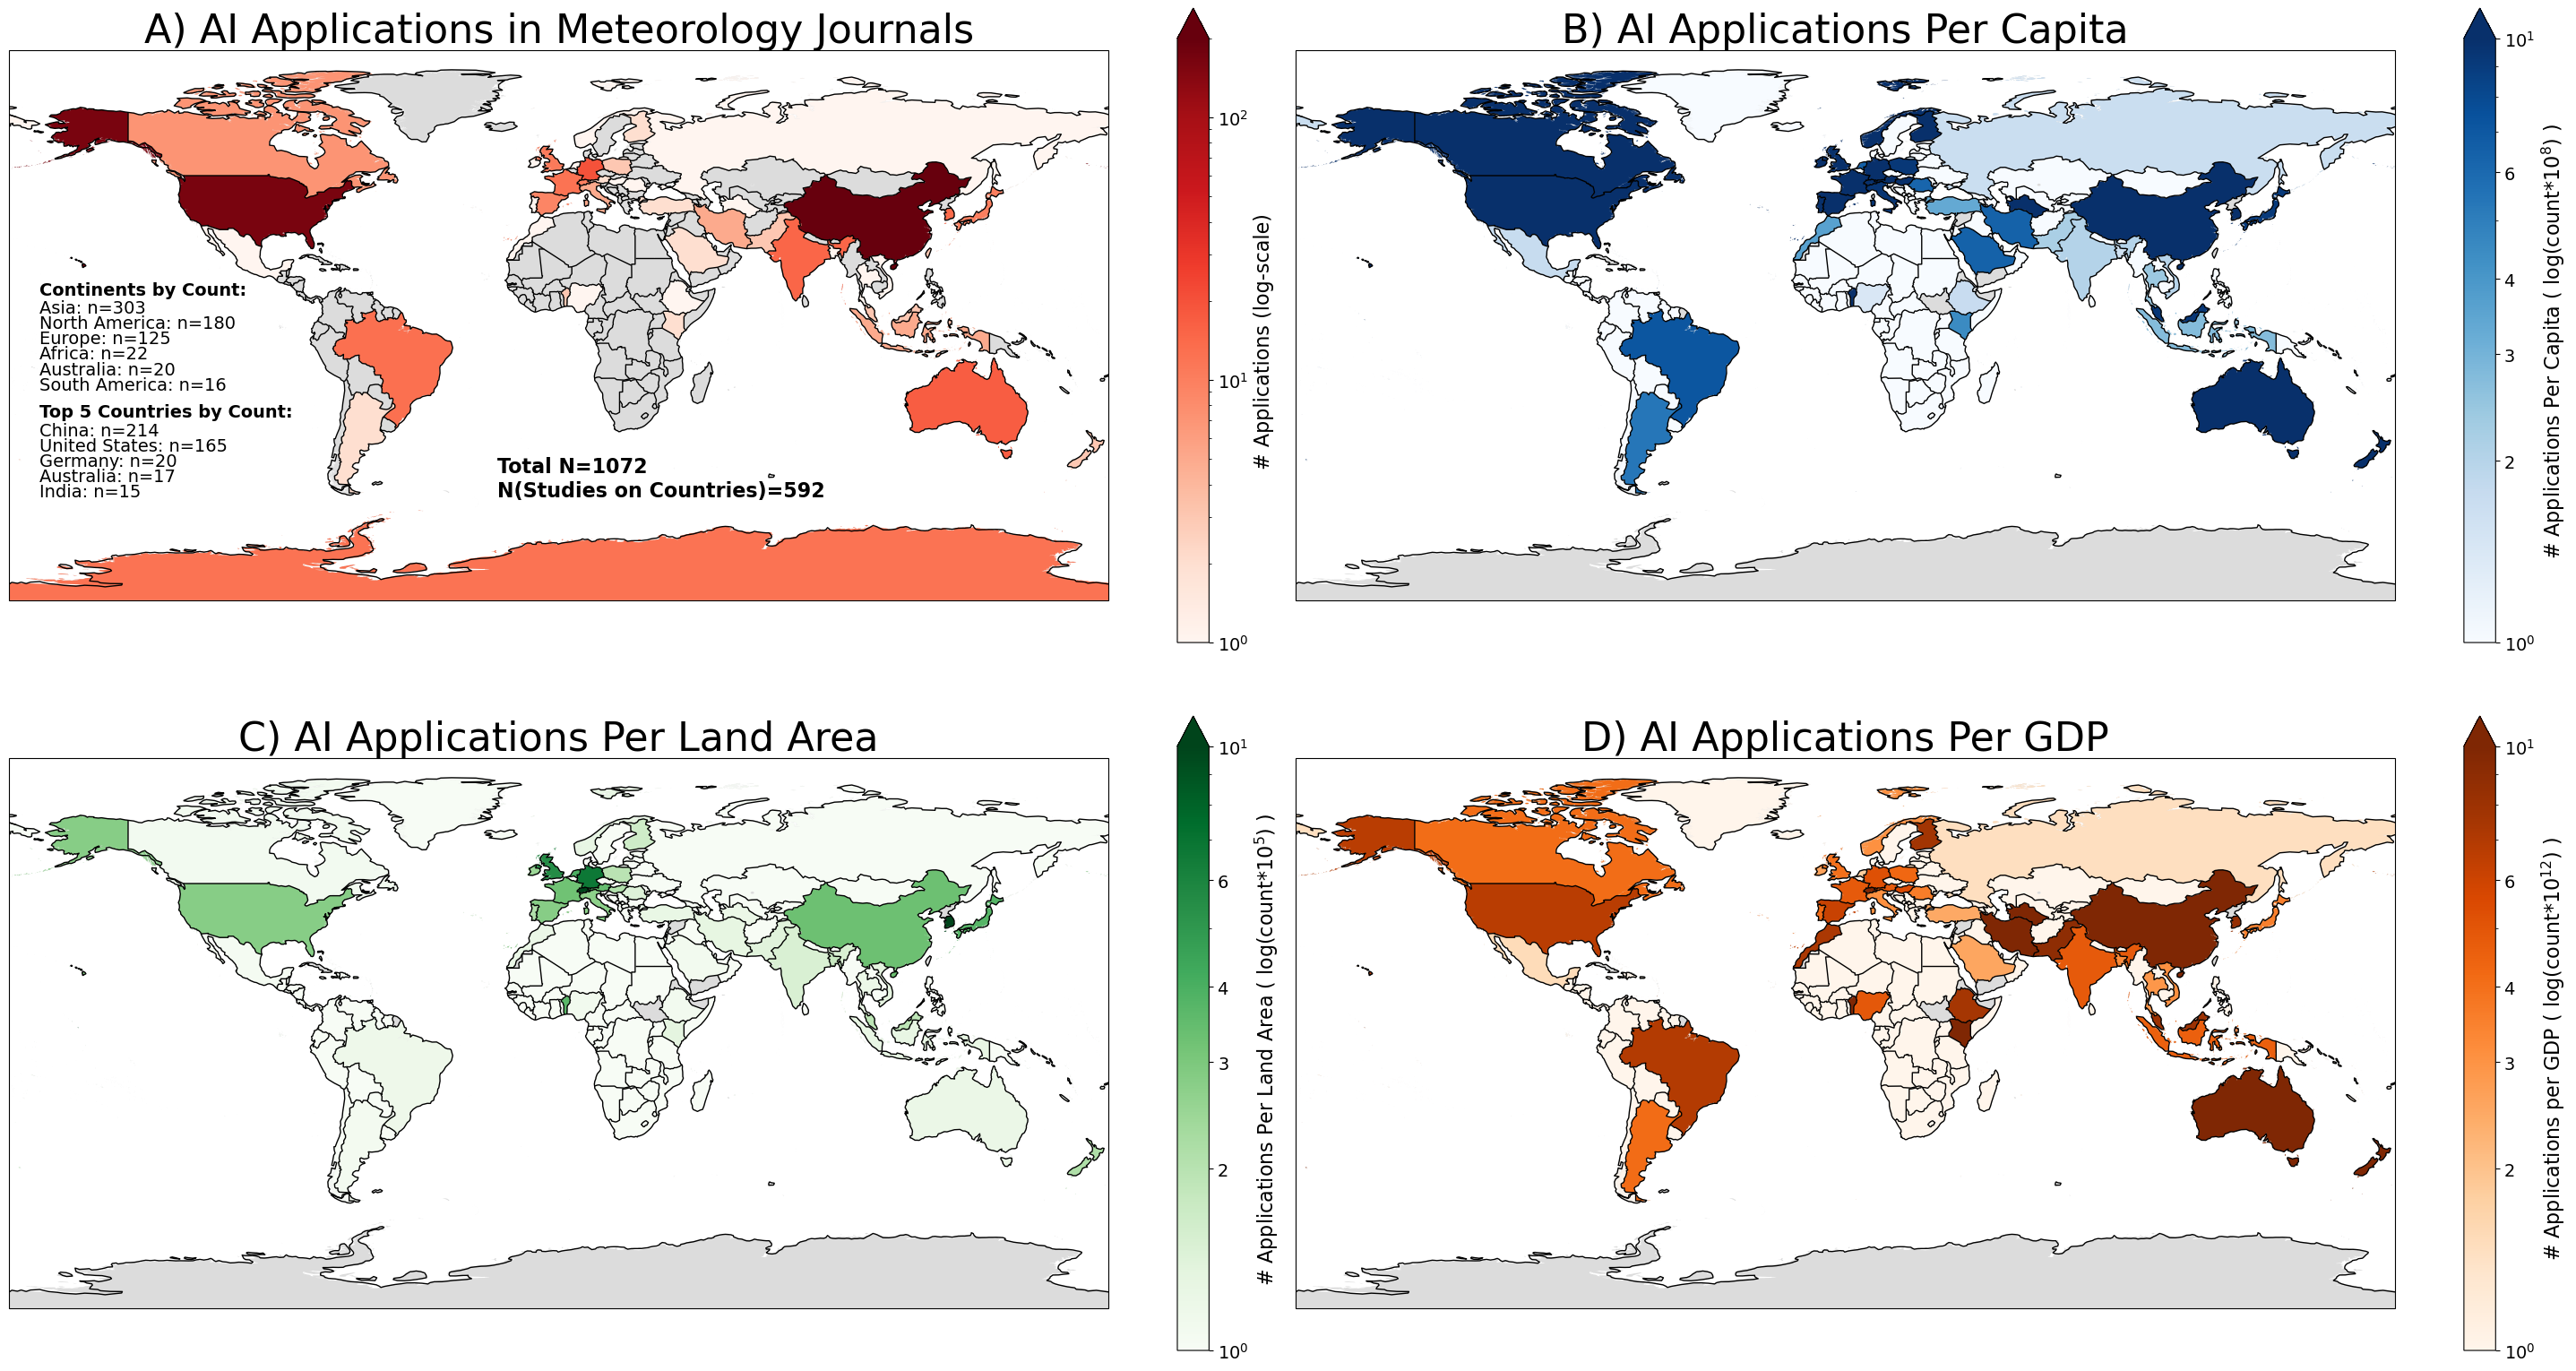

In [16]:
# Figure 1
fig = plt.figure(figsize=(30,20),layout='tight')

# Panel A: Heatmap of AI studies in meteorology
ax = fig.add_subplot(2,2,1,projection=ccrs.PlateCarree())

ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS)

cmap = mpl.colormaps.get_cmap('Reds')
norm = LogNorm(vmin=1,vmax=200) # Vmax of 200 since China has most studies with ~200

base_color='gainsboro'
# Initially color all countries gray
for index,country in df_shp.iterrows():
    poly = df_shp.loc[df_shp['ADMIN'] == df_shp['ADMIN']]['geometry'].values[index]
    mapped = ax.add_geometries(poly, crs=ccrs.PlateCarree(), facecolor=base_color, norm=norm,
                               edgecolor='none', zorder=1)

# Draw heatmap
for country,count in country_counts.items():
    # read the borders of the country in this loop
    poly = df_shp.loc[df_shp['ADMIN'] == country]['geometry'].values[0]
    log_count = math.log(count)

    poly_c = cmap(log_count/math.log(200)) # This line controls the shading of countries; apparently needed to divide by max of normalization to get this right
    
    # plot the country on a map
    if country == 'France': # Need to subset to remove French Guyana
        france = df_shp[df_shp['ADMIN'] == 'France']
        france_exp = france.explode(index_parts=False)
        mainland_france = france_exp.iloc[1] # Second index is mainland France

        mapped = ax.add_geometries(mainland_france['geometry'], crs=ccrs.PlateCarree(), facecolor=poly_c, cmap='Reds', norm=norm,
                                   edgecolor='none',zorder=1)

    else:
        mapped = ax.add_geometries(poly, crs=ccrs.PlateCarree(), facecolor=poly_c, cmap='Reds', norm=norm,
                               edgecolor='none', zorder=1)

    centroid = poly.centroid

cb = fig.colorbar(mapped,ax=ax,extend='max',shrink=0.6)
cb.set_label('# Applications (log-scale)',fontsize=16)
cb.ax.tick_params(labelsize=14)

ax.set_title('A) AI Applications in Meteorology Journals',
             fontsize=32)

# Annotate with country counts
ax.text(-20,-48,'Total N=1072',fontsize=16,fontweight='bold')
ax.text(-20,-56,f'N(Studies on Countries)={np.sum(list(country_counts.values()))}',fontsize=16,fontweight='bold')
        
ax.text(-170,10,'Continents by Count:',fontsize=14,fontweight='bold')
ax.text(-170,4,'Asia: n=303',fontsize=14)
ax.text(-170,-1,'North America: n=180',fontsize=14)
ax.text(-170,-6,'Europe: n=125',fontsize=14)
ax.text(-170,-11,'Africa: n=22',fontsize=14)
ax.text(-170,-16,'Australia: n=20',fontsize=14)
ax.text(-170,-21,'South America: n=16',fontsize=14)

ax.text(-170,-30,'Top 5 Countries by Count:',fontsize=14,fontweight='bold')
ax.text(-170,-36,'China: n=214',fontsize=14)
ax.text(-170,-41,'United States: n=165',fontsize=14)
ax.text(-170,-46,'Germany: n=20',fontsize=14)
ax.text(-170,-51,'Australia: n=17',fontsize=14)
ax.text(-170,-56,'India: n=15',fontsize=14)

# Panel B: # Publications / capita
ax = fig.add_subplot(2,2,2,projection=ccrs.PlateCarree())

ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS)

cmap_b = mpl.colormaps.get_cmap('Blues')
norm = LogNorm(vmin=1,vmax=10)

# Initially color all countries gray
for index,country in df_shp.iterrows():
    poly = df_shp.loc[df_shp['ADMIN'] == df_shp['ADMIN']]['geometry'].values[index]
    mapped = ax.add_geometries(poly, crs=ccrs.PlateCarree(), facecolor=base_color,
                               edgecolor='none', zorder=1)

# Draw heatmap
for country,count in per_capita_logdict.items():
    if country == 'Eswatini':
        country = 'eSwatini'
    elif country == 'Russian Federation':
        country = 'Russia'
    elif country == 'Serbia':
        country = 'Republic of Serbia'
    poly = df_shp.loc[df_shp['ADMIN'] == country]['geometry'].values[0]
    
    log_count = math.log(count)
    poly_c = cmap_b(log_count/math.log(10))
    
    # plot the country on a map
    if country == 'France': # Need to subset to remove French Guyana
        france = df_shp[df_shp['ADMIN'] == 'France']
        france_exp = france.explode(index_parts=False)
        mainland_france = france_exp.iloc[1] # Second index is mainland France

        mapped = ax.add_geometries(mainland_france['geometry'], crs=ccrs.PlateCarree(), facecolor=poly_c, cmap=cmap_b, norm=norm,
                                   edgecolor='none',zorder=1)

    else:
        mapped = ax.add_geometries(poly, crs=ccrs.PlateCarree(), facecolor=poly_c, cmap=cmap_b, norm=norm,
                               edgecolor='none', zorder=1)

    centroid = poly.centroid

cb = fig.colorbar(mapped,ax=ax,extend='max',shrink=0.6)
cb.set_label('# Applications Per Capita ( log(count*10$^8$) )',fontsize=16)
cb.set_ticks(ticks=[1,2,3,4,6,10],labels=['10$^0$','2','3','4','6','10$^1$'])
cb.ax.tick_params(labelsize=14)

ax.set_title('B) AI Applications Per Capita',
             fontsize=32)

# Panel C: Publications per land area
ax = fig.add_subplot(2,2,3,projection=ccrs.PlateCarree())

ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS)

cmap_c = mpl.colormaps.get_cmap('Greens')
norm = LogNorm(vmin=1,vmax=10)

# Initially color all countries gray
for index,country in df_shp.iterrows():
    poly = df_shp.loc[df_shp['ADMIN'] == df_shp['ADMIN']]['geometry'].values[index]
    mapped = ax.add_geometries(poly, crs=ccrs.PlateCarree(), facecolor=base_color,
                               edgecolor='none', zorder=1)

# Draw heatmap
for country,count in per_landarea_logdict.items():
    if country == 'Eswatini':
        country = 'eSwatini'
    elif country == 'Russian Federation':
        country = 'Russia'
    elif country == 'Serbia':
        country = 'Republic of Serbia'
    poly = df_shp.loc[df_shp['ADMIN'] == country]['geometry'].values[0]

    log_count = math.log(count)
    poly_c = cmap_c(log_count/math.log(10))
    
    # plot the country on a map
    if country == 'France': # Need to subset to remove French Guyana
        france = df_shp[df_shp['ADMIN'] == 'France']
        france_exp = france.explode(index_parts=False)
        mainland_france = france_exp.iloc[1] # Second index is mainland France

        mapped = ax.add_geometries(mainland_france['geometry'], crs=ccrs.PlateCarree(), facecolor=poly_c, cmap=cmap_c, norm=norm,
                                   edgecolor='none',zorder=1)

    else:
        mapped = ax.add_geometries(poly, crs=ccrs.PlateCarree(), facecolor=poly_c, cmap=cmap_c, norm=norm,
                               edgecolor='none', zorder=1)

    centroid = poly.centroid

cb = fig.colorbar(mapped,ax=ax,extend='max',shrink=0.6)
cb.set_label('# Applications Per Land Area ( log(count*10$^5$) )',fontsize=16)
cb.set_ticks(ticks=[1,2,3,4,6,10],labels=['10$^0$','2','3','4','6','10$^1$'])
cb.ax.tick_params(labelsize=14)

ax.set_title('C) AI Applications Per Land Area',
             fontsize=32)

# Panel D: Publications per land area
ax = fig.add_subplot(2,2,4,projection=ccrs.PlateCarree())

ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS)

cmap_d = mpl.colormaps.get_cmap('Oranges')
norm = LogNorm(vmin=1,vmax=10)

# Initially color all countries gray
for index,country in df_shp.iterrows():
    poly = df_shp.loc[df_shp['ADMIN'] == df_shp['ADMIN']]['geometry'].values[index]
    mapped = ax.add_geometries(poly, crs=ccrs.PlateCarree(), facecolor=base_color,
                               edgecolor='none', zorder=1)

# Draw heatmap
for country,count in per_gdp_logdict.items():
    if country == 'Eswatini':
        country = 'eSwatini'
    elif country == 'Russian Federation':
        country = 'Russia'
    elif country == 'Serbia':
        country = 'Republic of Serbia'
    poly = df_shp.loc[df_shp['ADMIN'] == country]['geometry'].values[0]

    ### Block for regular normalization
    log_count = math.log(count)
    poly_c = cmap_d(log_count/math.log(10))
    ###
    
    # plot the country on a map
    if country == 'France': # Need to subset to remove French Guyana
        france = df_shp[df_shp['ADMIN'] == 'France']
        france_exp = france.explode(index_parts=False)
        mainland_france = france_exp.iloc[1] # Second index is mainland France

        mapped = ax.add_geometries(mainland_france['geometry'], crs=ccrs.PlateCarree(), facecolor=poly_c, cmap=cmap_d, norm=norm,
                                   edgecolor='none',zorder=1)

    else:
        mapped = ax.add_geometries(poly, crs=ccrs.PlateCarree(), facecolor=poly_c, cmap=cmap_d, norm=norm,
                               edgecolor='none', zorder=1)

    centroid = poly.centroid

cb = fig.colorbar(mapped,ax=ax,extend='max',shrink=0.6)
cb.set_label('# Applications per GDP ( log(count*10$^{12}$) )',fontsize=16)
cb.set_ticks(ticks=[1,2,3,4,6,10],labels=['10$^0$','2','3','4','6','10$^1$'])
cb.ax.tick_params(labelsize=14)

ax.set_title('D) AI Applications Per GDP',
             fontsize=32)

In [17]:
os.chdir('../FiguresForPaper')
fig.savefig('Fig1.jpg',bbox_inches='tight',dpi=300)
#print(os.getcwd())